In [7]:
!pip install pca


   ---------------------------------------- 0/5 [datazets]
   -------- ------------------------------- 1/5 [colourmap]
   ---------------- ----------------------- 2/5 [adjusttext]
   ------------------------ --------------- 3/5 [scatterd]
   -------------------------------- ------- 4/5 [pca]
   -------------------------------- ------- 4/5 [pca]
   ---------------------------------------- 5/5 [pca]



In [13]:
import os
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# from sklearn.decomposition import PCA
from pca import pca

os.chdir(r"E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets")

In [9]:
milk  = pd.read_csv('milk.csv', index_col = 0)       # animal and milk ingredients dataset
milk


,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10
CAMEL,87.7,3.5,3.4,4.8,0.71
BISON,86.9,4.8,1.7,5.7,0.90
BUFFALO,82.1,5.9,7.9,4.7,0.78
GUINEA PIG,81.9,7.4,7.2,2.7,0.85


In [17]:
model = pca(normalize= True)
results = model.fit_transform(milk, row_labels = milk.index)

results

[21-10-2026 11:19:03] [pca.pca] [INFO] Extracting column labels from dataframe.
[21-10-2026 11:19:03] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[21-10-2026 11:19:03] [pca.pca] [INFO] PCA reduction performed to capture at least 95.0% explained variance using 5 columns of the input data.
[21-10-2026 11:19:03] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:19:03] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:19:03] [pca.pca] [INFO] Compute explained variance.
[21-10-2026 11:19:03] [pca.pca] [INFO] The top 2 principal component(s) explains >= 95.00% of the explained variance.
[21-10-2026 11:19:03] [pca.pca] [INFO] The PCA reduction is performed on 5 variables (columns) of the input dataframe.
[21-10-2026 11:19:03] [pca.pca] [INFO] Fit using PCA.
[21-10-2026 11:19:03] [pca.pca] [INFO] Compute loadings and PCs.
[21-10-2026 11:19:03] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[21-10-20

{'loadings':         water   protein       fat   lactose       ash
 PC1  0.472944 -0.466570 -0.448683  0.482891 -0.352330
 PC2  0.352855  0.320941 -0.476037  0.059515  0.736435,
 'PC':                  PC1       PC2
 HORSE       2.435175 -0.231478
 ORANGUTAN   2.258736 -0.693148
 MONKEY      2.335861 -0.663328
 DONKEY      2.318677 -0.273815
 HIPPO       2.060294 -1.019199
 CAMEL       1.301536  0.137303
 BISON       1.282742  0.622667
 BUFFALO     0.505068  0.088235
 GUINEA PIG -0.255502  0.287373
 CAT        -0.051008  0.470136
 FOX         0.429017  0.459312
 LLAMA       1.364034  0.309224
 MULE        2.012658 -0.192807
 PIG        -0.000100  0.788138
 ZEBRA       1.390928 -0.012660
 SHEEP       0.513120  0.321365
 DOG        -0.982829  0.725239
 ELEPHANT    0.302294 -1.079878
 RABBIT     -2.798474  2.288793
 RAT        -1.309609  0.774032
 DEER       -2.212053  0.345036
 REINDEER   -2.345616  0.310003
 WHALE      -2.892787  0.721121
 SEAL       -4.133773 -2.200801
 DOLPHIN    -3.5

[21-10-2026 11:22:28] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[21-10-2026 11:22:28] [scatterd.scatterd] [INFO] Create scatterplot


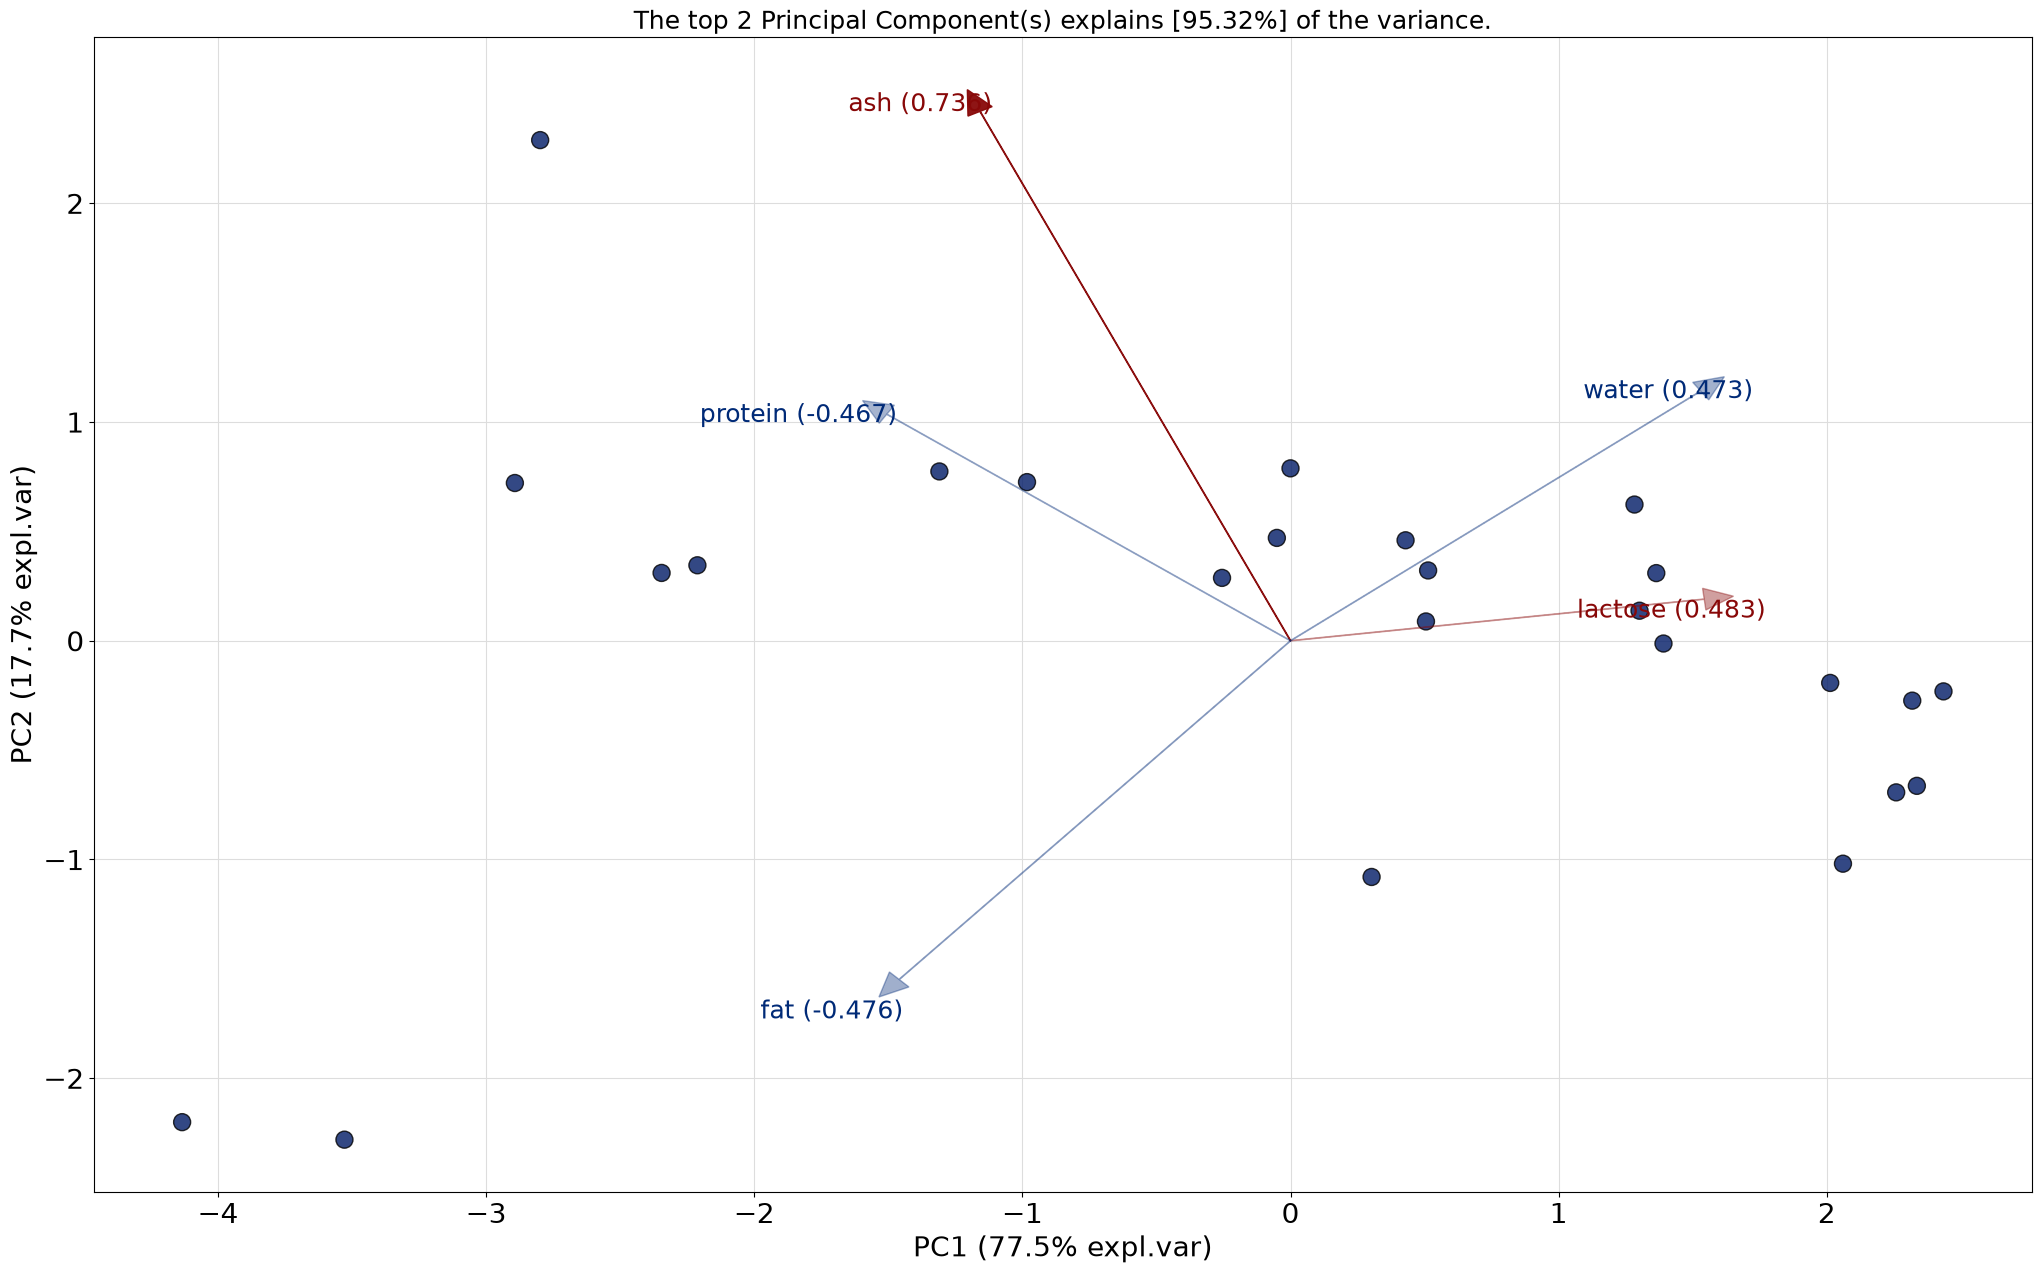

In [19]:
model.biplot() 
plt.show()

[21-10-2026 11:24:12] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[21-10-2026 11:24:12] [scatterd.scatterd] [INFO] Create scatterplot


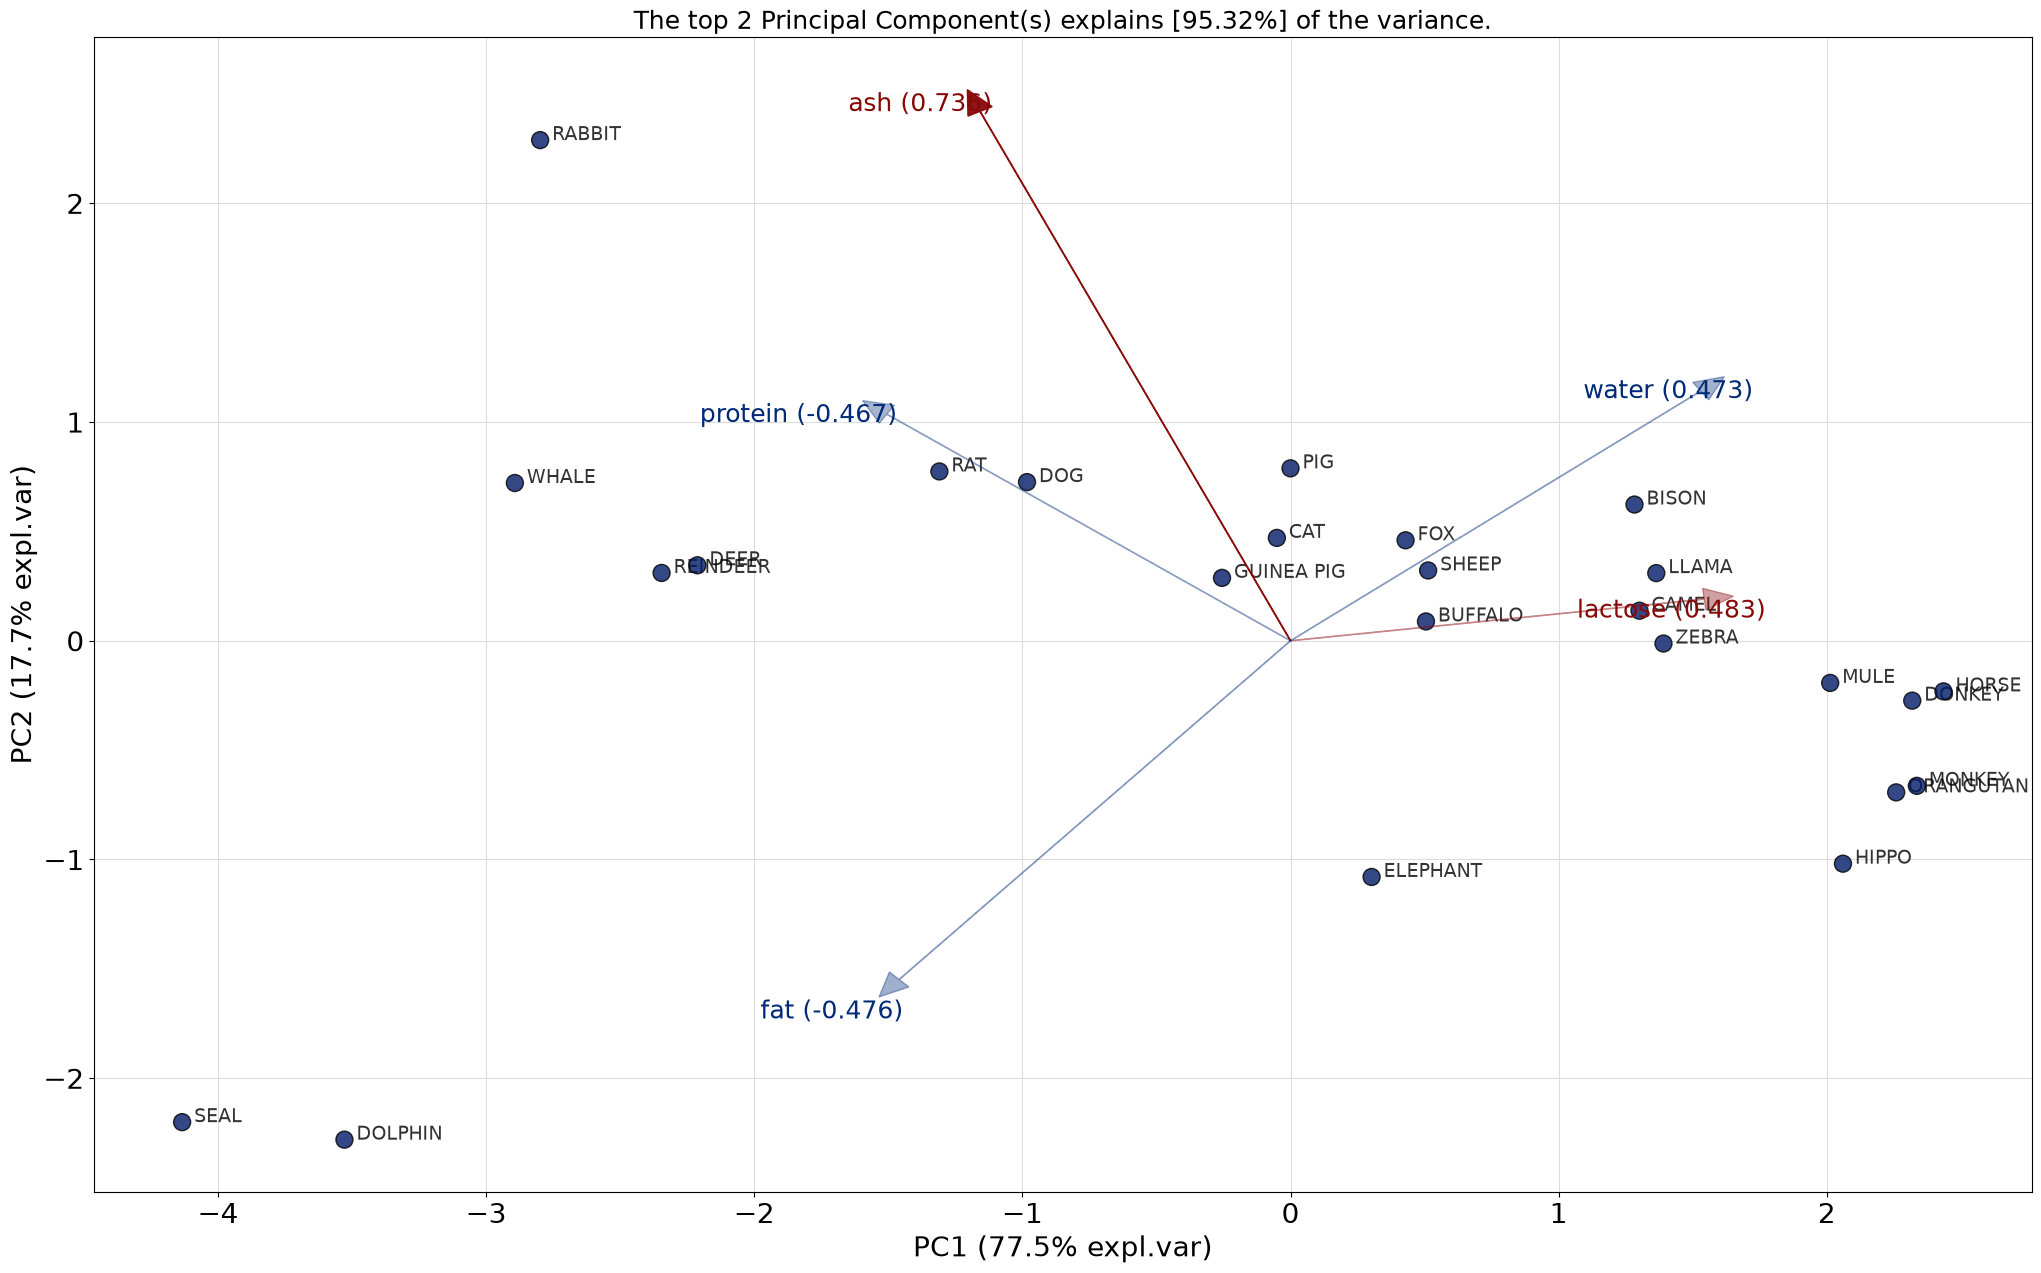

In [24]:
pc_coords = results['PC']
 
model.biplot()
# Loop through each animal and place its index name next to its point
for animal in pc_coords.index:
    x = pc_coords.loc[animal, 'PC1']
    y = pc_coords.loc[animal, 'PC2']
    plt.text(x, y, f'  {animal}', fontsize=14, alpha=0.8)

plt.show()

[21-10-2026 11:27:50] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[21-10-2026 11:27:50] [scatterd.scatterd] [INFO] Create scatterplot


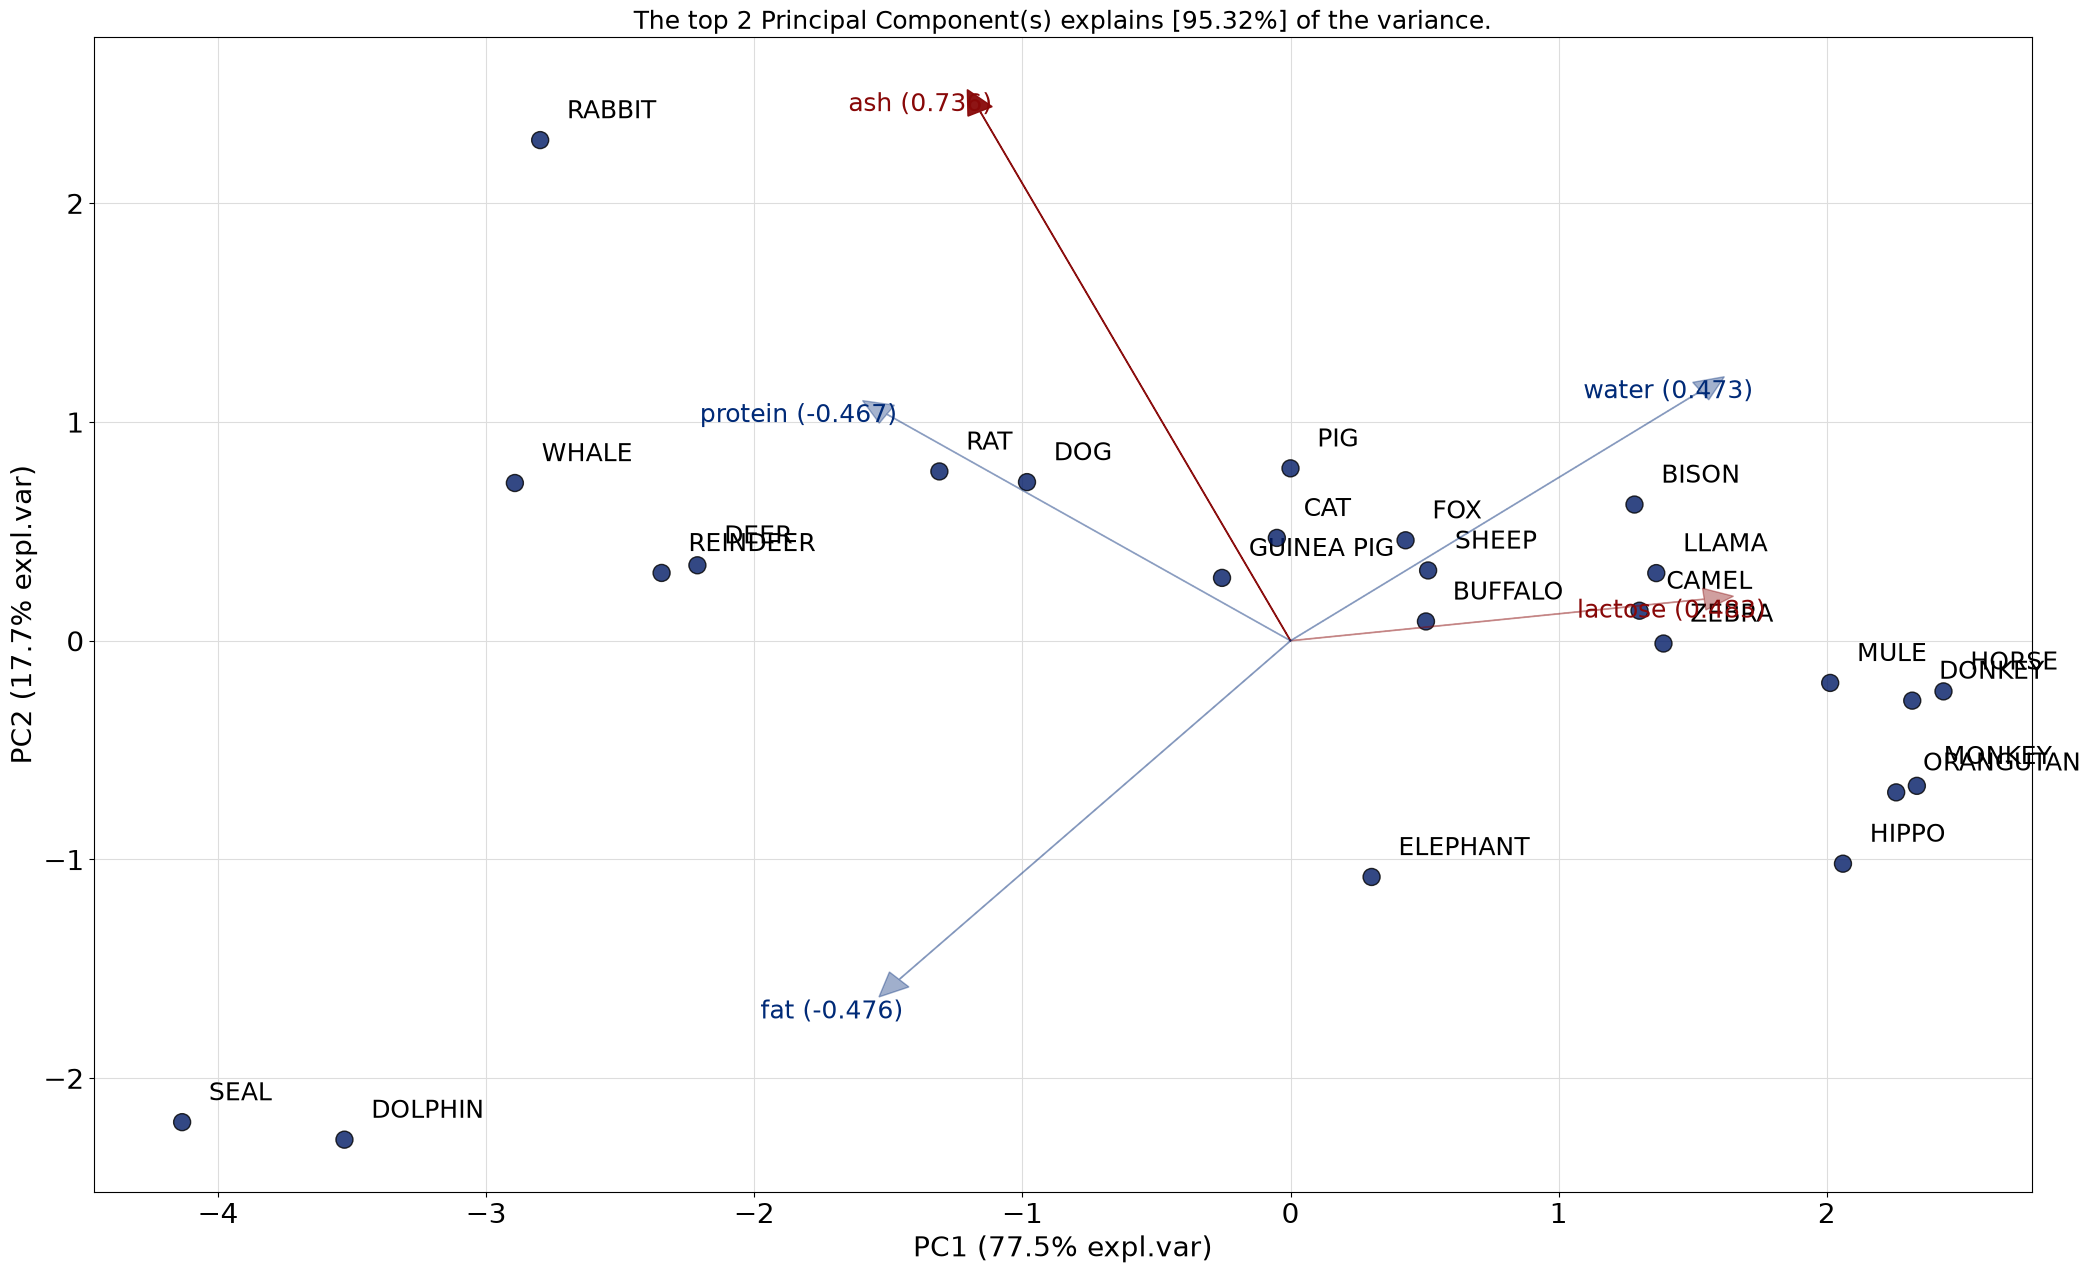

In [27]:
scaler = StandardScaler().set_output(transform='pandas')
scl_milk = scaler.fit_transform(milk)

prcomp = PCA().set_output(transform='pandas')
pca_data = prcomp.fit_transform(scl_milk)
pca_data

model.biplot()
for i in range(len(milk)):
    plt.text(pca_data['pca0'].iloc[i]+0.1, pca_data['pca1'].iloc[i]+0.1, milk.index[i])
plt.show()